# Robynne Le Roux - Assingment 2 Perceptron Image Classification

In [14]:
'''imports'''
import numpy as np #Imports the entire module
from PIL import Image #Imports specific items from a module
import glob, os #finding files and paths 
import matplotlib.pyplot as plt #for testing
import random
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

### 1. Data processing

In [4]:
'''load the Simpsons-MNIST 28x28 RGB/grayscale images; create training set and validation set
- reduce vectors and normalise so suitable for perceptron'''

labels = { # Hard-coded mapping - since we know names and that they are of thos format
    "bart_simpson": 0,
    "charles_montgomery_burns": 1,
    "homer_simpson": 2,
    "krusty_the_clown": 3,
    "lisa_simpson": 4,
    "marge_simpson": 5,
    "milhouse_van_houten": 6,
    "moe_szyslak": 7,
    "ned_flanders": 8,
    "principal_skinner": 9
}
short_names = { #for readibility
    0: "bart",
    1: "burns",
    2: "homer",
    3: "krusty",
    4: "lisa",
    5: "marge",
    6: "milhouse",
    7: "moe",
    8: "ned",
    9: "skinner"
}
def load_all_images(folder):
    """Load images into a dictionary: {label: [images]} """
    
    map_images = {0: [], 1: [], 2: [], 3: [], 4: [], 5: [], 6: [], 7: [], 8: [], 9: []}
    
    for key, value in labels.items():
        
        class_folder = os.path.join(folder, key)    
        for filepath in glob.glob(os.path.join(class_folder,"*.jpg")): #used  https://pillow.readthedocs.io/en/stable/reference/Image.htm 
            
            img = Image.open(filepath)
            arr = np.asarray(img)  
            map_images[value].append(arr)            
    
    # Convert lists to numpy arrays
    for value in map_images:
        
        map_images[value] = np.array(map_images[value]) #array containg [r g b] for eahc pixel relating to each image relating to each sim
    
    raw_map = flatten_map(map_images)
    
    norm_map = normalise_images(map_images)
    
    return raw_map, norm_map
    
def normalise_images(map_images):
    '''normalise from [0,255] to [0,1]  '''
    '''since in pixels the min is always 0 and the max is always 255'''
    normalised_map = {}
    
    for key, value in map_images.items():
        
        normalised_map[key] = (value - 0 ) / (255.0  - 0) #because uint8 images store pixel values from 0 to 255
        
    return flatten_map(normalised_map) 
    
def flatten_map(normalised_map):
    
    """Flatten each image in the map to a 1D vector."""
    flat_map = {}
    
    for key, value in normalised_map.items():
        # Check if images are RGB (4D) or grayscale (3D)
        
        if value.ndim == 4:  # RGB: (num_images, height, width, channels - rgb)
            
            flat_size = value.shape[1] * value.shape[2] * value.shape[3]
            
        elif value.ndim == 3:  # Grayscale: (num_images, height, width)
            
            flat_size = value.shape[1] * value.shape[2]

        elif value.ndim == 2:  # Already flattened
            
            flat_map[key] = value
            continue
            
        else:
            
            raise ValueError(f"Unexpected shape for key '{key}': {value.shape}")  #DISCLAIMER: AI HELPED WITH THIS - I WAS GETTING ERRORS BEFORE

        flat_images = value.reshape(value.shape[0], flat_size)  # One row per image
        flat_map[key] = flat_images

    return flat_map

#replace this with user directory
base_directory = "data/dataset" #all images are in subfolders but this is general path

rgb_train_raw, rgb_train_norm = load_all_images(os.path.join(base_directory, "rgb" , "train")) #do not change since explained how to set up dataset in README file
rgb_test_raw, rgb_test_norm  = load_all_images(os.path.join(base_directory, "rgb", "test"))

grayscale_train_raw, grayscale_train_norm = load_all_images(os.path.join(base_directory, "grayscale" , "train"))
grayscale_test_raw, grayscale_test_norm  = load_all_images(os.path.join(base_directory, "grayscale", "test"))

def split_maps(map_images, val_ratio = 0.25, seed = 42): #in tutorial said: "let validation be the size of test" so we need both to be 2000 (ie split 75/25)
    
    '''Split each class's images into training and validation maps by slicing.
       Shuffled train and validation set in tut'''
    #rand = np.random.default_rng(seed) # since seed = None we have non-deterministic splits
    rng = np.random.default_rng(seed) #better since 'uniform' and 'gaussian' etc rely on random sampling
    train_map = {}
    val_map = {}

    for key, value in map_images.items():
        
        n_total = value.shape[0] # Total number of images for this label
        n_val = int(n_total * val_ratio)

        idx = rng.permutation(n_total)  # reproducible shuffle -> best for predicting which normilisation and configurations are best
        val_idx = idx[:n_val] #since we want same amt of test and validation for each simpson
        train_idx = idx[n_val:]
        
        train_map[key] = value[train_idx]
        val_map[key] = value[val_idx]

    return train_map, val_map

'''implement'''
rgb_train_part, rgb_val_part = split_maps(rgb_train_norm) #splits 75 : 25 -confirm correct split (ie just used what told in tut)
grayscale_train_part, grayscale_val_part = split_maps(grayscale_train_norm)

### Testing for loading data (for myself)

Label 0: 600 images
Label 1: 600 images
Label 2: 600 images
Label 3: 600 images
Label 4: 600 images
Label 5: 600 images
Label 6: 600 images
Label 7: 600 images
Label 8: 600 images
Label 9: 600 images
Total train rgb images: 8000
Total test rgb images: 2000
Total train rgb images: 8000
Total test rgb images: 2000
Label 0
Number of images 800
Shape of images array (800, 2352)
Data type float64
Label 0
Number of images 800
Shape of images array (800, 784)
Data type float64


Shape of image array: (800, 2352)

Flattened vector 1 (first 10 values):
[0.31764706 0.57647059 0.70980392 0.26666667 0.53333333 0.67843137
 0.27843137 0.55294118 0.74509804 0.27058824]

Flattened vector 2 (first 10 values):
[0.34509804 0.22352941 0.         0.3372549  0.22352941 0.00392157
 0.3372549  0.23921569 0.01960784 0.31764706]

Flattened vector 3 (first 10 values):
[0.20392157 0.27058824 0.10588235 0.16862745 0.2627451  0.17647059
 0.30588235 0.45098039 0.51372549 0.26666667]
Label 0: Total=600, Train=600, Va

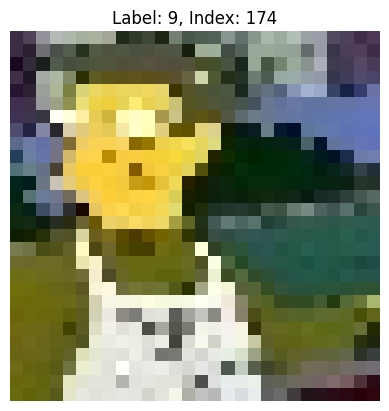

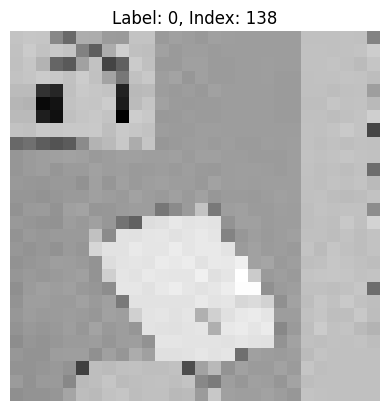

In [43]:
#print Number of images per character -just test train rgb -others will follow correctness/ incorrectness
for label, imgs in rgb_train_part.items():
    print(f"Label {label}: {len(imgs)} images")

total_train_rgb = sum(len(imgs) for imgs in rgb_train_norm.values())
print("Total train rgb images:", total_train_rgb) #want 8000
total_test_rgb = sum(len(imgs) for imgs in rgb_test_norm.values())
print("Total test rgb images:", total_test_rgb) #want 2000
total_train_grey = sum(len(imgs) for imgs in grayscale_train_norm.values())
print("Total train rgb images:", total_train_grey) #want 8000
total_test_grey = sum(len(imgs) for imgs in grayscale_test_norm.values())
print("Total test rgb images:", total_test_grey) #want 2000

first_label = list(rgb_train_norm.keys())[0] #testing for bart
first_label_images = rgb_train_norm[first_label]
print("Label", first_label)
print("Number of images", len(first_label_images))
print("Shape of images array", first_label_images.shape) #So 800 images and each individual image has shape (28, 28, 3) - 28x28 pixels with rgb
print("Data type", first_label_images.dtype) #uint8 = unsigned 8-bit integer - BEFORE NORMALISING ; float64 - AFTER NORMALISING

second_label = list(grayscale_train_norm.keys())[0]
second_label_images = grayscale_train_norm[second_label]
print("Label", second_label)
print("Number of images", len(second_label_images))
print("Shape of images array", second_label_images.shape) #So 800 images and each individual image has shape (28, 28) - 28x28 pixels in grayscale
print("Data type", second_label_images.dtype) 

print("\n")
bart_vectors = rgb_train_norm[0]  # Already flattened and normalised - Bart's label is 0
print("Shape of image array:", bart_vectors.shape)  # Should be (num_images, 2352)

# Print first 3 flattened vectors (first 10 values of each for brevity)
for i in range(3):
    print(f"\nFlattened vector {i+1} (first 10 values):")
    print(bart_vectors[i][:10])  # Just the first 10 values to keep it readable

# Test split summary
for label in rgb_train_part:
    total = len(rgb_train_part[label])
    train = len(rgb_train_part[label])
    val = len(rgb_val_part[label])
    print(f"Label {label}: Total={total}, Train={train}, Val={val}")

def show_random_image(split_map, grayscale=False):
    '''Show a random image from a split map (train/val/test).'''
    # pick a random class (digit/character label)
    label = np.random.choice(list(split_map.keys()))
    images = split_map[label]

    # pick a random index within this class
    idx = np.random.randint(len(images))
    img = images[idx]

    # reshape for display
    if grayscale:
        img = img.reshape(28, 28)
        plt.imshow(img, cmap="gray")
    else:
        img = img.reshape(28, 28, 3)
        plt.imshow(img)

    plt.title(f"Label: {label}, Index: {idx}")
    plt.axis("off")
    plt.show()

#pixelated — which is expected from a 28×28 resolution!!!!!!!! NB
# For RGB test set
show_random_image(rgb_test_norm, grayscale = False)

# For grayscale test set
show_random_image(grayscale_test_norm, grayscale = True)


### 2. Multi-class perceptron implementation

In [6]:
'''using skeleton from perceptron tutorial'''

class BinaryPerceptron:
    
    '''implements the perceptron learning rule and a predict function returning a binary label. '''
    
    #self refers to the current instance of the class. It’s how each object keeps track of its own data.
    #def __init__(self, n_inputs, alpha = 0.1): #n_inputs is number of features in your input vector (e.g. 2352 for flattened RGB)
        
        #self.weights = np.ones(n_inputs, dtype=float) #one weight per input
        #self.bias = 0.1 #small constant added to the net input
        #self.learning_rate = alpha #learning rate

    #updated constructor for 4. Hyperparameter tuning 
    '''Implements perceptron learning rule with FLEXIBLE weight init.'''
    def __init__(self, n_inputs, alpha = 0.1, init_strategy = "zeros"):
        
        self.learning_rate = alpha

        if init_strategy == "zeros":
            
            self.weights = np.zeros(n_inputs, dtype=float)
            
        elif init_strategy == "ones":
            
            self.weights = np.ones(n_inputs, dtype=float)
            
        elif init_strategy == "uniform":
            
            self.weights = np.random.uniform(-0.01, 0.01, n_inputs)
            
        elif init_strategy == "gaussian":
            
            self.weights = np.random.normal(0, 0.01, n_inputs)
            
        else:
            
            raise ValueError(f"Unknown init_strategy: {init_strategy}")

        self.bias = 0.0

    def predict(self, x): #used claude to help with debugging had self and x wrong way around!!!
        
        x = np.array(x, dtype=float)
        net_input = np.dot(x, self.weights) + self.bias
        return 1 if net_input >= 0 else 0 #step activation at 0

    def apply_learning_rule(self, x, y): #perceptron learning rule is designed to be applied repeatedly across the training data
        
        y_hat = self.predict(x) # x is flattened image. returns 0 or 1
        error = y - y_hat
        self.weights += self.learning_rate * error * x
        self.bias += self.learning_rate * error
    
    def __repr__(self): #defines how objects are represented — nb for debugging
        
        return f"TrainablePerceptron(weights={self.weights}, bias={self.bias:.3f}, alpha={self.alpha})"
        
class MultiClassPerceptron:
    
    '''maintain one binary perceptron per class and predict by selecting the class with the highest score'''
    '''uses BinaryPerceptron class'''

    '''NB Try alpha2 = 0.05 or 0.1 and see how fast the model learns
       Track accuracy over epochs to find the sweet spot!!!!!!!!'''
    #def __init__(self, n_inputs, n_classes = 10, alpha2 = 0.01): #lower aplha helps prevent conflicting updates across classes
        
        #self.n_classes = n_classes
        #self.learning_rate = alpha2
        #self.perceptrons = []
        
        #for i in range(n_classes): #creates 10 binary perceptrons, one for each class
            
            #self.perceptrons.append(BinaryPerceptron(n_inputs, alpha2)) #inputs stay the same since trying to make the prediction ie whole point of perceptron

    #updated constructor for 4. Hyperparameter tuning 
    '''Extend MultiClassPerceptron to pass init strategy'''

    def __init__(self, n_inputs, n_classes = 10, alpha2 = 0.01, init_strategy = "zeros"): #added init_strategy
        
        self.n_classes = n_classes #how many binary classifiers to build
        self.perceptrons = []
        
        for _ in range(n_classes): #using _ Python convention since we dont use the variable
                
            p = BinaryPerceptron(n_inputs, alpha2, init_strategy)
            self.perceptrons.append(p)    
    
    def _score(self, x, perceptron): #since slightly different than binary classification need "confidence" for each class
        
        x = np.array(x, dtype = float)
        return np.dot(x, perceptron.weights) + perceptron.bias

    def predict(self, x): #returns with highes score
        
        scores = []
        for p in self.perceptrons:
            
            score = self._score(x, p)
            scores.append(score)
            
        return np.argmax(scores)

    def train(self, x, y): #Train using one-vs-rest strategy.
        
        for i in range(self.n_classes):
            
            target = 1 if i == y else 0 #if we found the correct label, train with target = 1
            self.perceptrons[i].apply_learning_rule(x, target) #use  binary version perceptron learning rule

    def __repr__(self):
        
        return f"TrainablePerceptron(weights={self.weights}, bias={self.bias:.3f}, alpha={self.learning_rate})"

### 3. Training

In [48]:
'''Implements a perceptron training loop. Shuffles the order of examples between epochs.
   Implements different stopping criteria -fixed nr epochs, error threshold
   using skeleton from perceptron tutorial'''

def accuracy(model, input_data, true_labels): 
    """Compute classification accuracy."""
    
    correct = 0 #counter for how many predictions match the true labels
    total = len(true_labels)
    
    for i in range(total):
        
        x = input_data[i]
        y = true_labels[i]
        y_pred = model.predict(x) 
        
        if y_pred == y:
            
            correct += 1
            
    return correct / total #this is the accuracy

def shuffle_training(training_data, label_of_training, rng): #generlaised shuffle method to improve oop
    '''shuffle training data for each epoc'''
    
    idx = np.random.permutation(len(training_data))
    return training_data[idx], label_of_training[idx]

"""
Train perceptron with stopping criteria:
- METHOD 1: fixed nr epochs
- METHOD 2: stop if training error less than error_threshold
"""
def train_fixed(model, training_data, label_of_training, val_data = None, val_labels = None, max_epochs = 50, seed = 42):
    
    '''method 1'''
    rng = np.random.default_rng(seed)
    history = [] # Track accuracy per epoch
    for epoch in range(1, max_epochs + 1):
        
        shuffled_data, shuffled_labels = shuffle_training(training_data, label_of_training, rng) # Shuffle training data to avoid learning order bias
        
        for i in range(len(shuffled_data)): # Train model on each sample
            
            model.train(shuffled_data[i], shuffled_labels[i])
            
        train_acc = accuracy(model, training_data, label_of_training) # Evaluate accuracy 
        val_acc = accuracy(model, val_data, val_labels) if val_data is not None else None
        history.append((train_acc, val_acc))
        
        #print(f"Epoch {epoch}: Train Acc={train_acc:.3f}", end="")
        
        #if val_acc is not None:
            
            #print(f", Val Acc={val_acc:.3f}")
        
    return history

def train_error_threshold(model, training_data, label_of_training, val_data = None, val_labels = None, max_epochs = 150, error_threshold = 0.1, seed = 42): 
    
    '''method 2'''
    rng = np.random.default_rng(seed)
    history = [] # Track accuracy per epoch
    for epoch in range(1, max_epochs + 1):
        
        shuffled_data, shuffled_labels = shuffle_training(training_data, label_of_training, rng) # Shuffle training data to avoid learning order bias
        
        for i in range(len(shuffled_data)): # Train model on each sample
            
            model.train(shuffled_data[i], shuffled_labels[i])
            
        train_acc = accuracy(model, training_data, label_of_training) # Evaluate accuracy
        val_acc = accuracy(model, val_data, val_labels) if val_data is not None else None
        history.append((train_acc, val_acc))
        
        #print(f"Epoch {epoch}: Train Acc={train_acc:.3f}", end="")
        
        #if val_acc is not None:
            
            #print(f", Val Acc={val_acc:.3f}")
            
        if 1 - train_acc <= error_threshold:
            
            print("Stopped early (error threshold reached), Val Acc={val_acc:.3f})")
            break
            
    return history    

def map_to_xy(map_data): #specific method for how I've implemented my solution
    
    """Convert {label: images} dict to (training_data, label_of_training)."""
    data_list, label_list = [], []
    
    for label, imgs in map_data.items():
        
        data_list.append(imgs)
        label_list.extend([label] * len(imgs))
        
    training_data = np.vstack(data_list)
    label_of_training = np.array(label_list)
    
    return training_data, label_of_training

### 3. Implemet Training

In [50]:
'''implement above methods'''
# RGB model - train fixed ephocs and error threshold
# re-initializing fresh models for each training call (made the mistake of testing on already tested data)

training_data_rgb, label_of_training_rgb = map_to_xy(rgb_train_part)
training_data_grey, label_of_training_grey = map_to_xy(grayscale_train_part)

val_data_rgb, val_labels_rgb = map_to_xy(rgb_val_part)
val_data_grey, val_labels_grey = map_to_xy(grayscale_val_part)

p_rgb_fixed = MultiClassPerceptron(n_inputs = training_data_rgb.shape[1], n_classes = 10, alpha2 = 0.01)
history_rgb_fixed = train_fixed(p_rgb_fixed, training_data_rgb, label_of_training_rgb, val_data_rgb, val_labels_rgb)
print("RGB - Training using fixed epochs done")

p_rgb_error = MultiClassPerceptron(n_inputs = training_data_rgb.shape[1], n_classes = 10, alpha2 = 0.01)
history_rgb_error = train_error_threshold(p_rgb_error, training_data_rgb, label_of_training_rgb, val_data_rgb, val_labels_rgb)
print("RGB - Train using error threshold done")

# Grayscale model
p_grey_fixed = MultiClassPerceptron(n_inputs = training_data_grey.shape[1], n_classes = 10, alpha2 = 0.01)
history_grey_fixed = train_fixed(p_grey_fixed, training_data_grey, label_of_training_grey, val_data_grey, val_labels_grey)
print("Greyscale - Train using fixed epochs done")

p_grey_error = MultiClassPerceptron(n_inputs = training_data_grey.shape[1], n_classes = 10, alpha2 = 0.01)
history_grey_error = train_error_threshold(p_grey_error, training_data_grey, label_of_training_grey, val_data_grey, val_labels_grey)
print("Greyscale - Train using error threshold done")

print(f"\nRGB (Fixed Epochs) - Max Train Acc: {max([x[0] for x in history_rgb_fixed]):.3f}, Max Val Acc: {max([x[1] for x in history_rgb_fixed]):.3f}")
print(f"RGB (Error Threshold) - Max Train Acc: {max([x[0] for x in history_rgb_error]):.3f}, Max Val Acc: {max([x[1] for x in history_rgb_error]):.3f}")
print(f"Greyscale (Fixed Epochs) - Max Train Acc: {max([x[0] for x in history_grey_fixed]):.3f}, Max Val Acc: {max([x[1] for x in history_grey_fixed]):.3f}")
print(f"Greyscale (Error Threshold) - Max Train Acc: {max([x[0] for x in history_grey_error]):.3f}, Max Val Acc: {max([x[1] for x in history_grey_error]):.3f}")

RGB - Training using fixed epochs done
RGB - Train using error threshold done
Greyscale - Train using fixed epochs done
Greyscale - Train using error threshold done

RGB (Fixed Epochs) - Max Train Acc: 0.706, Max Val Acc: 0.372
RGB (Error Threshold) - Max Train Acc: 0.781, Max Val Acc: 0.381
Greyscale (Fixed Epochs) - Max Train Acc: 0.433, Max Val Acc: 0.215
Greyscale (Error Threshold) - Max Train Acc: 0.477, Max Val Acc: 0.222


### 3. Accuracy plot

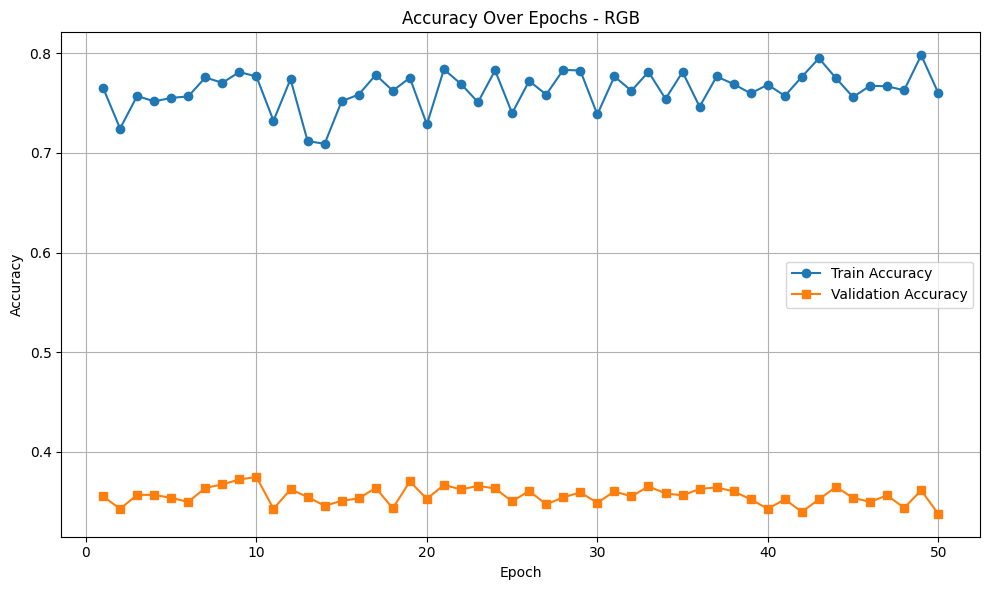

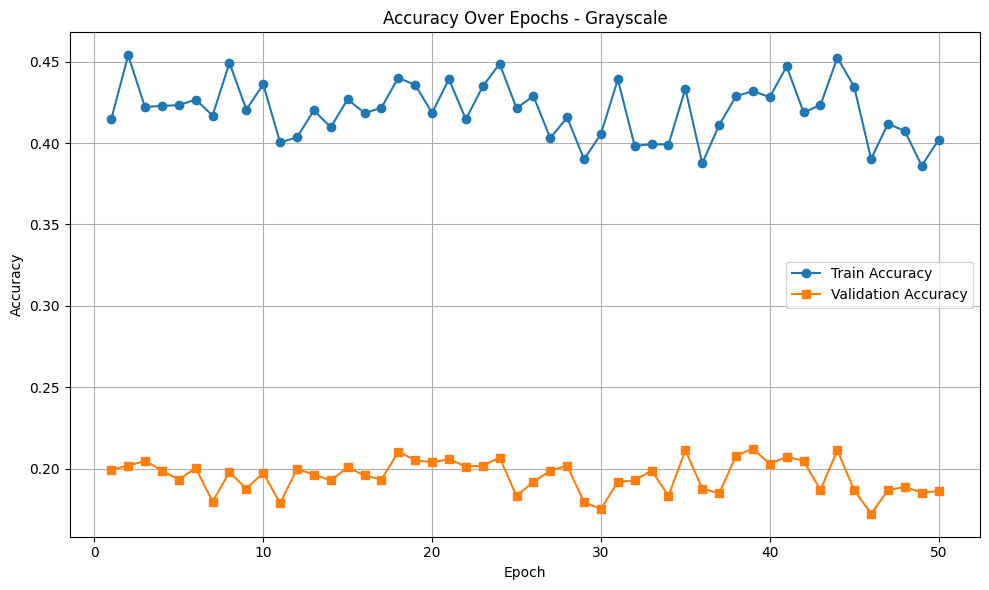

In [51]:
def plot_training_history(history, model_colour="Model"):
    epochs = range(1, len(history) + 1)
    train_acc = [h[0] for h in history]
    val_acc = [h[1] for h in history]

    plt.figure(figsize=(10, 6))
    plt.plot(epochs, train_acc, label="Train Accuracy", marker='o')
    plt.plot(epochs, val_acc, label="Validation Accuracy", marker='s')
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.title(f"Accuracy Over Epochs - {model_colour}")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

history_rgb = train_fixed(final_rgb, training_data_rgb, label_of_training_rgb, val_data_rgb, val_labels_rgb, max_epochs=50)
plot_training_history(history_rgb, model_colour="RGB")

history_grey = train_fixed(final_grey, training_data_grey, label_of_training_grey, val_data_grey, val_labels_grey, max_epochs=50)
plot_training_history(history_grey, model_colour="Grayscale")

### 4. Hyperparameter tuning

In [9]:
'''Training + tuning 2 models: 1 using RGB inputs & 1 using grayscale inputs. Find combination of hyperparameters that yields the best performance'''

#edittedt BinaryPerceptron and MultiClassPerceptron (in 2. Multi-class perceptron implementation) to allow for flexible weight -(zero / constant / uniform / Gaussian).

#normalisation techniques (no normalisation / z-score normalisation). -already have [0,1] normalisation

def normalise_none(map_images):
    """No normalisation, just flatten."""
    
    return flatten_map(map_images)

# Tuning learning rate 
def normalise_zscore(images):
    
    for k in images:
        
        img = images[k]
        images[k] = ( img - np.mean(img) ) / np.std(img) #z-score normalisation (ie mean becomes 0 and standard deviation becomes 1)
        
    return flatten_map(images)

results = []  # Track all results for later analysis - Store globally
def tune_model(train_map, val_map, modality = "RGB"):
    '''#Grid search loop'''
    
    normalisers = {
        "none": normalise_none,
        "min-max": normalise_images, #[0-1]
        "zscore": normalise_zscore
    }
    
    learning_rates = [0.0005, 0.001, 0.005, 0.01, 0.05]
    init_strategies = ["zeros", "ones", "uniform", "gaussian"]

    best_acc = 0 # Track best validation accuracy
    best_params = None # Track best config (norm, lr, init)

    np.random.seed(42) #just convention
    
    for norm_name, norm_func in normalisers.items(): # Loop over all normalisation methods
        
        # Apply normalisation separately to train and val
        normed_train = norm_func(train_map)
        normed_val   = norm_func(val_map)

        train_data, train_labels = map_to_xy(normed_train)
        val_data, val_labels     = map_to_xy(normed_val)

        for lr in learning_rates:
            
            for init in init_strategies:

                # Create a model with current hyperparameters -ie train and then get best result
                np.random.seed(42)  # ensures identical weight init across runs
                model = MultiClassPerceptron( 
                    n_inputs = train_data.shape[1],
                    n_classes = 10,
                    alpha2 = lr,
                    init_strategy = init
                )                
                # Train for fixed number of epochs - since more efficient
                train_fixed(
                    model,
                    training_data = train_data,
                    label_of_training = train_labels,
                    val_data = val_data,
                    val_labels = val_labels,
                    max_epochs = 20,
                    seed = 42
                )
                val_acc = accuracy(model, val_data, val_labels) # Evaluate on validation set

                #print(f"{modality} | Norm={norm_name}, LR={lr}, Init={init} - Val Acc={val_acc:.3f}")
                config = norm_name + "_" + str(lr) + "_" + init
                results.append((modality, config, val_acc))                

                # Update best config if this is better then previous
                if val_acc > best_acc:
                    best_acc = val_acc
                    best_params = (norm_name, lr, init)

    print("\nBest {} config: ".format(modality))
    print("Normalisation: {}".format(best_params[0]))
    print("Learning Rate: {}".format(best_params[1]))
    print("Initialisation: {}".format(best_params[2]))
    print("Validation Accuracy: {:.3f}".format(best_acc))

    return {
        "modality": modality,
        "normalisation": best_params[0],
        "learning_rate": best_params[1],
        "initialisation": best_params[2],
        "val_accuracy": best_acc
    }

# Run tuning properly
best_rgb_config = tune_model(rgb_train_part, rgb_val_part, "RGB")
best_grey_config = tune_model(grayscale_train_part, grayscale_val_part, "Grayscale")


Best RGB config: 
Normalisation: none
Learning Rate: 0.0005
Initialisation: ones
Validation Accuracy: 0.413

Best Grayscale config: 
Normalisation: none
Learning Rate: 0.0005
Initialisation: ones
Validation Accuracy: 0.257


### 4. Visualise Hyperparameter tuning 

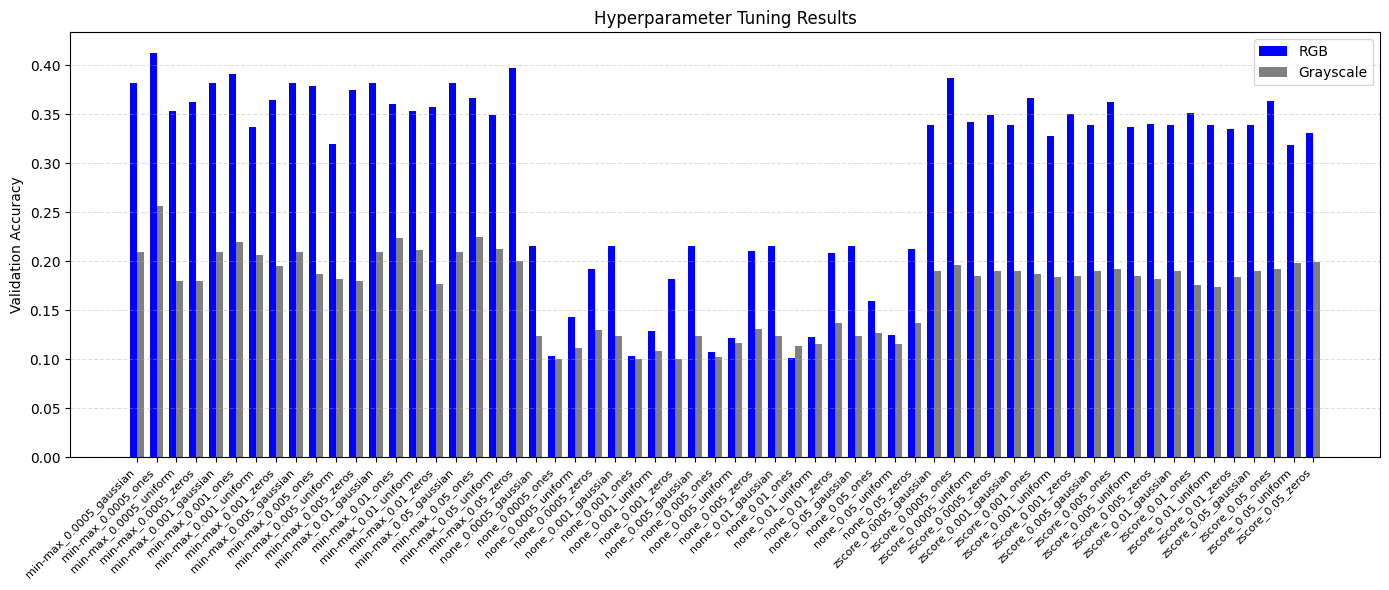

In [23]:
'''implemented because of "including visualizations" - in submission requirements'''
def plot_tuning_results(results):
    configs = sorted(set(r[1] for r in results)) # Extract unique config labels
    
    
    # Get accuracy scores for each modality
    rgb_scores = [r[2] for r in results if r[0] == "RGB"]
    grey_scores = [r[2] for r in results if r[0] == "Grayscale"]

    x = np.arange(len(configs)) # X-axis positions 
    width = 0.35 # Width of each bar

    # Create plot
    fig, ax = plt.subplots(figsize=(14, 6))
    ax.bar(x - width/2, rgb_scores, width, label='RGB', color='blue')
    ax.bar(x + width/2, grey_scores, width, label='Grayscale', color='grey')
    plt.subplots_adjust(left=0.08)
    
    #use claude for help
    ax.set(title='Hyperparameter Tuning Results', ylabel='Validation Accuracy')
    ax.set_xticks(x)
    ax.set_xticklabels(configs, rotation=45, ha='right', fontsize=8) #USED AI - BETTER FIT
    ax.legend()
    ax.grid(True, axis = 'y', linestyle='--', alpha = 0.4)

    plt.tight_layout() #avoid layout overflow
    plt.show()

plot_tuning_results(results)

### 5. Evaluation


Final RGB model trained with:
Modality: RGB
Normalisation: none
Learning_rate: 0.0005
Initialisation: ones
Val_accuracy: 0.413

Evaluating RGB model on Validation Set:

Per-Class Metrics (Validation Set RGB):
Character                       Acc      Prec       Rec        F1
bart                          0.360     0.300     0.360     0.327
burns                         0.290     0.335     0.290     0.311
homer                         0.240     0.287     0.240     0.262
krusty                        0.520     0.531     0.520     0.525
lisa                          0.360     0.306     0.360     0.331
marge                         0.720     0.529     0.720     0.610
milhouse                      0.440     0.442     0.440     0.441
moe                           0.405     0.420     0.405     0.412
ned                           0.260     0.388     0.260     0.311
skinner                       0.390     0.408     0.390     0.399

Overall Evaluation (Validation Set RGB):
Accuracy              

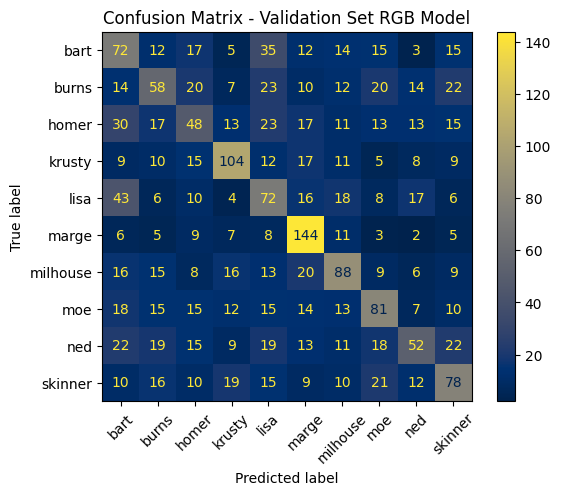


Evaluating RGB model on Test Set:

Per-Class Metrics (Test Set Validation Set RGB):
Character                       Acc      Prec       Rec        F1
bart                          0.305     0.298     0.305     0.301
burns                         0.255     0.315     0.255     0.282
homer                         0.110     0.386     0.110     0.171
krusty                        0.810     0.270     0.810     0.405
lisa                          0.325     0.295     0.325     0.310
marge                         0.345     0.945     0.345     0.505
milhouse                      0.550     0.324     0.550     0.408
moe                           0.240     0.306     0.240     0.269
ned                           0.185     0.507     0.185     0.271
skinner                       0.260     0.456     0.260     0.331

Overall Evaluation (Test Set Validation Set RGB):
Accuracy                   0.3385
Precision                  0.4102
Recall                     0.3385
F1 Score                   0.3254


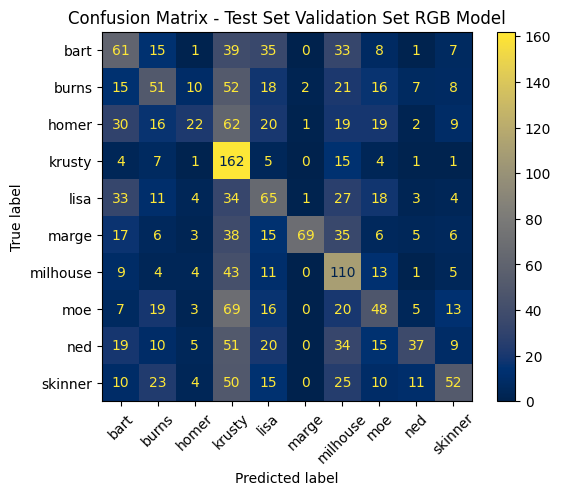


Final Grayscale model trained with:
Modality: Grayscale
Normalisation: none
Learning_rate: 0.0005
Initialisation: ones
Val_accuracy: 0.2565

Evaluating Grayscale model on Validation Set:

Per-Class Metrics (Validation Set Grayscale):
Character                       Acc      Prec       Rec        F1
bart                          0.110     0.183     0.110     0.138
burns                         0.225     0.269     0.225     0.245
homer                         0.145     0.155     0.145     0.150
krusty                        0.190     0.191     0.190     0.190
lisa                          0.240     0.172     0.240     0.200
marge                         0.280     0.257     0.280     0.268
milhouse                      0.180     0.195     0.180     0.187
moe                           0.255     0.245     0.255     0.250
ned                           0.225     0.231     0.225     0.228
skinner                       0.250     0.207     0.250     0.226

Overall Evaluation (Validation Set Gra

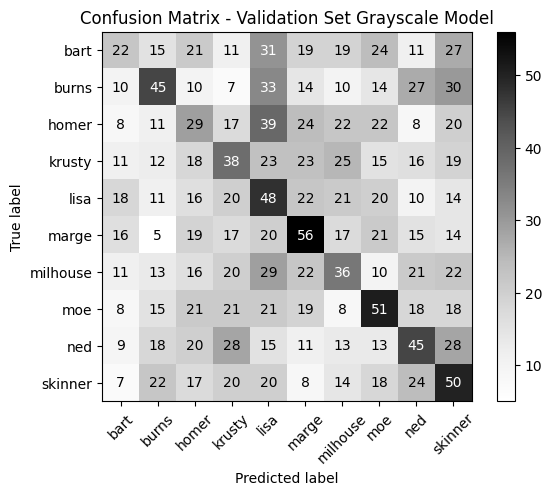


Evaluating Grayscale model on Test Set:

Per-Class Metrics (Test Set Validation Set Grayscale):
Character                       Acc      Prec       Rec        F1
bart                          0.090     0.151     0.090     0.113
burns                         0.250     0.278     0.250     0.263
homer                         0.195     0.177     0.195     0.186
krusty                        0.155     0.163     0.155     0.159
lisa                          0.210     0.173     0.210     0.190
marge                         0.300     0.271     0.300     0.285
milhouse                      0.285     0.285     0.285     0.285
moe                           0.210     0.212     0.210     0.211
ned                           0.225     0.238     0.225     0.231
skinner                       0.265     0.221     0.265     0.241

Overall Evaluation (Test Set Validation Set Grayscale):
Accuracy                   0.2185
Precision                  0.2170
Recall                     0.2185
F1 Score          

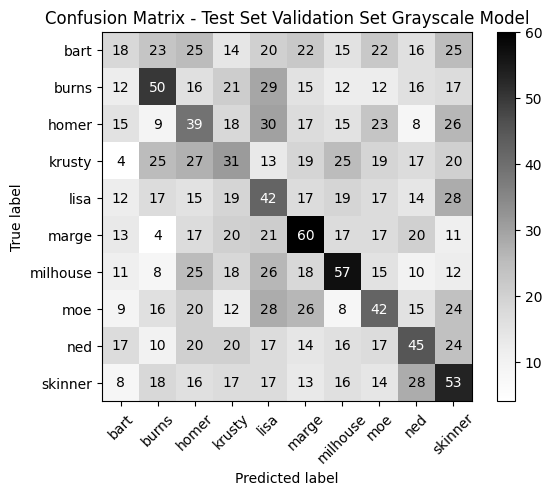

In [56]:
''' evaluate hyperparameters found above on test data'''
''' DSICLAIMER: I DID USE AI TO HELP ME ALIGN SOME OF THE TABLES'''
    
#Raw Test Maps to Arrays
test_data_rgb, test_labels_rgb = map_to_xy(normalise_images(rgb_test_raw)) #using min-max normilisation
test_data_grey, test_labels_grey = map_to_xy(normalise_zscore(grayscale_test_raw)) #using zscore normilisation

# Train final RGB model
final_rgb = MultiClassPerceptron(
    n_inputs = training_data_rgb.shape[1],
    n_classes = 10,
    # match paramters found from step 4!!!
    alpha2 = best_rgb_config["learning_rate"],
    init_strategy = best_rgb_config["initialisation"]  
)
train_fixed( #more efficient method
    final_rgb,
    training_data = training_data_rgb,
    label_of_training = label_of_training_rgb,
    val_data = val_data_rgb,
    val_labels = val_labels_rgb,
    max_epochs = 20
)
# Train final Grayscale model
final_grey = MultiClassPerceptron(
    n_inputs = training_data_grey.shape[1],
    n_classes = 10,
    # match paramters found from step 4!!!
    alpha2 = best_grey_config["learning_rate"],
    init_strategy = best_grey_config["initialisation"]
)
train_fixed(
    final_grey,
    training_data = training_data_grey,
    label_of_training = label_of_training_grey,
    val_data = val_data_grey,
    val_labels = val_labels_grey,
    max_epochs = 20
)

def evaluate(model, test_data, test_labels, model_colour, short_names):
    """
    Evaluate a trained perceptron model on test data.    """

    preds = np.array([model.predict(x) for x in test_data]) #Return predicted labels for a batch of input data.

    # Per-class metrics
    precision_per_class = precision_score(test_labels, preds, average=None, zero_division=0)
    recall_per_class = recall_score(test_labels, preds, average=None, zero_division=0)
    f1_per_class = f1_score(test_labels, preds, average=None, zero_division=0)
    
    # Per-class accuracy
    accuracy_per_class = []
    
    for i in range(10):
        
        true_class = np.array(test_labels) == i
        correct_preds = (preds == i) & true_class
        acc_i = correct_preds.sum() / true_class.sum() if true_class.sum() > 0 else 0.0
        accuracy_per_class.append(acc_i)
        
    print(f"\nPer-Class Metrics ({model_colour}):")
    print(f"{'Character':<25} {'Acc':>9} {'Prec':>9} {'Rec':>9} {'F1':>9}")
    for i in range(10):
        print(f"{short_names[i]:<25} {accuracy_per_class[i]:>9.3f} {precision_per_class[i]:>9.3f} {recall_per_class[i]:>9.3f} {f1_per_class[i]:>9.3f}")

    # over all metrics
    # average = 'macro' is scoring strategy used in multi-class classification to give equals weight to each class
    acc = accuracy_score(test_labels, preds)
    prec = precision_score(test_labels, preds, average = 'macro', zero_division = 0)
    rec = recall_score(test_labels, preds, average = 'macro', zero_division = 0)
    f1 = f1_score(test_labels, preds, average = 'macro', zero_division = 0)

    print(f"\nOverall Evaluation ({model_colour}):")
    print(f"{'Accuracy':<20} {acc:>12.4f}")
    print(f"{'Precision ':<20} {prec:>12.4f}")
    print(f"{'Recall ':<20} {rec:>12.4f}")
    print(f"{'F1 Score ':<20} {f1:>12.4f}")

    # Confusion matrix
    cm = confusion_matrix(test_labels, preds, labels = list(range(10)))
    disp = ConfusionMatrixDisplay(confusion_matrix  = cm, display_labels = [short_names[i] for i in range(10)])
    cmap = 'cividis' if "RGB" in model_colour else 'Greys'
    disp.plot(cmap = cmap, xticks_rotation = 45)
    plt.title(f"Confusion Matrix - {model_colour} Model")
    plt.show()

    return {
        "accuracy": acc,
        "precision_macro": prec,
        "recall_macro": rec,
        "f1_macro": f1,
        "precision_per_class": precision_per_class,
        "recall_per_class": recall_per_class,
        "f1_per_class": f1_per_class,
        "accuracy_per_class": accuracy_per_class
    }

def compare_val_and_test(model, val_data, val_labels, test_data, test_labels, model_colours, model_colour, short_names):
    '''always for validating validation and test set'''
    
    print(f"\nEvaluating {model_colours} model on Validation Set:")
    model_colour = "Validation Set " + model_colour
    metrics_val = evaluate(model, val_data, val_labels, model_colour, short_names)

    print(f"\nEvaluating {model_colours} model on Test Set:")
    model_colour = "Test Set " + model_colour
    metrics_test = evaluate(model, test_data, test_labels, model_colour, short_names)

    return metrics_val, metrics_test
    
print("\nFinal RGB model trained with:")

for k, v in best_rgb_config.items():
    
    print(f"{k.capitalize()}: {v}")
    
metrics_rgb_val, metrics_rgb_test = compare_val_and_test(final_rgb, val_data_rgb, val_labels_rgb, test_data_rgb, test_labels_rgb, "RGB", "RGB", short_names)

print("\nFinal Grayscale model trained with:")

for k, v in best_grey_config.items():
    
    print(f"{k.capitalize()}: {v}")

metrics_grey_val, metrics_grey_test = compare_val_and_test(final_grey, val_data_grey, val_labels_grey, test_data_grey, test_labels_grey, "Grayscale", "Grayscale", short_names)

### 6 RGB vs grayscale analysis -visualisations

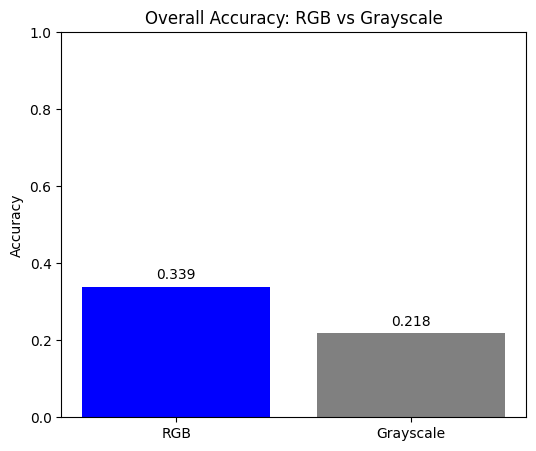

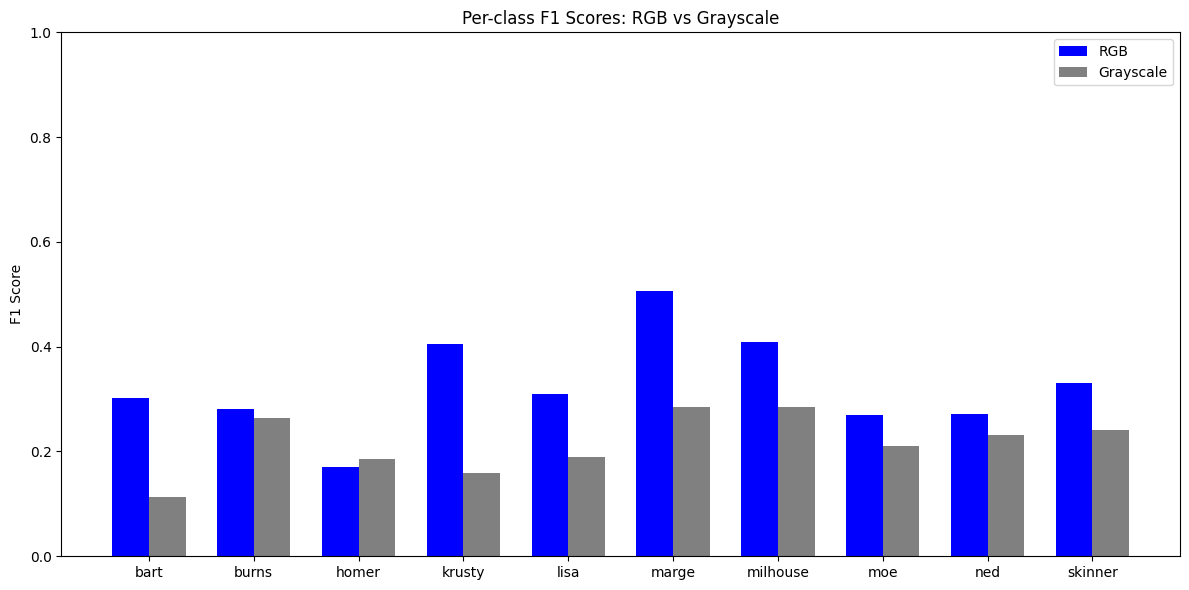

In [57]:
def plot_rgb_vs_grey_analysis(metrics_rgb, metrics_grey, short_names):
    
    #Plot 1: Overall Accuracy 
    plt.figure(figsize=(6, 5))
    bars = plt.bar(["RGB", "Grayscale"], [metrics_rgb["accuracy"], metrics_grey["accuracy"]], color=["blue", "grey"])
    
    plt.ylabel("Accuracy")
    plt.title("Overall Accuracy: RGB vs Grayscale")
   
    plt.ylim(0, 1.0)
    for bar, val in zip(bars, [metrics_rgb["accuracy"], metrics_grey["accuracy"]]):
        plt.text(bar.get_x() + bar.get_width()/2, val + 0.02, f"{val:.3f}", ha="center")
    plt.show()
    
    # Plot 2: Per-class F1 comparison 
    x = np.arange(len(display_labels))
    width = 0.35
    fig, ax = plt.subplots(figsize=(12, 6))
    
    ax.bar(x - width/2, metrics_rgb["f1_per_class"], width, label="RGB", color="blue")
    ax.bar(x + width/2, metrics_grey["f1_per_class"], width, label="Grayscale", color="grey")

    ax.set_xticks(x)
    ax.set_xticklabels(short_names)
    ax.set_ylabel("F1 Score")
    ax.set_title("Per-class F1 Scores: RGB vs Grayscale")
    ax.legend()
    plt.ylim(0, 1.0)
    plt.tight_layout()
    plt.show()

#print(short_names)  
display_labels = [short_names[i] for i in range(len(short_names))] # Convert dictionary to ordered list of names
#print(display_labels) 
plot_rgb_vs_grey_analysis(metrics_rgb_test, metrics_grey_test, display_labels)